# Student Academic Performance Prediction using Deep Neural Networks

Course project for 24CAI0306 Deep Neural Networks (B.E. CSE-AIML, Semester 5).

**Question.** Will a student finish the year **at risk**, meaning a final grade G3 below 10 out of 20 (the Portuguese pass mark)?

**Data.** UCI Student Performance, Portuguese course: 649 students, 30 demographic, family, school and lifestyle features, plus the period grades G1 and G2.

**Two scenarios.**
- *Late term*: after the 2nd grading period, so G1 and G2 are known.
- *Early warning*: start of the year, no grades yet.

**Model.** A PyTorch multilayer perceptron tuned with Optuna. It is compared with a majority-class baseline, a one-line rule, logistic regression, random forest and XGBoost, all under the same cross-validation.

The code lives in `src/`, one file per stage, and every section below calls it. The notebook and the scripts therefore always agree. A full run takes about 3 minutes on a laptop CPU.

| # | Section |
|---|---|
| 1 | Setup |
| 2 | Data audit and EDA |
| 3 | Target and locked test split |
| 4 | Preprocessing and feature selection |
| 5 | The DNN: architecture and training loop |
| 6 | Hardware: CPU vs GPU |
| 7 | Hyperparameter tuning (Optuna) |
| 8 | DNN vs traditional ML, then the test set |
| 9 | The same network in Keras |
| 10 | What the network computes, in plain NumPy |
| 11 | Predicting individual students |
| 12 | Conclusions |

## 1. Setup

In [1]:
import os, sys, subprocess

os.environ.setdefault("OMP_NUM_THREADS", "1")   # set before torch/xgboost load: avoids a libomp crash on macOS, and 1 thread is fastest on data this small
os.environ.setdefault("KERAS_BACKEND", "torch")  # Keras 3 runs on PyTorch here, so TensorFlow isn't needed

if not os.path.exists("src"):  # on Kaggle: fetch the project code and data from GitHub
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/auraCodesKM/student-performance-dnn.git"], check=True)
    os.chdir("student-performance-dnn")
sys.path.insert(0, os.getcwd())

import inspect, json, time
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from IPython.display import Image, Markdown, display
from sklearn.pipeline import Pipeline

from src import evaluate, tune
from src.data import SEED, load_data, make_preprocessor, split
from src.eda import audit, figures
from src.model import MLP, DNNClassifier
%matplotlib inline

print("python", sys.version.split()[0], "| torch", torch.__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

python 3.12.2 | torch 2.15.0 | scikit-learn 1.9.1 | pandas 3.1.1


## 2. Data audit and EDA

Each check below led to a pipeline decision (all of them are listed in `DECISIONS.md`):
- No missing values and no duplicates, so no imputation is needed.
- Only 15.4% of students are at risk. Accuracy alone is misleading, so **macro-F1** is the main metric.
- All 15 students with G3 = 0 also have 0 absences. They most likely dropped out or missed the final exam, so they are kept as real fails.
- G2 alone predicts G3 well, so the rule "at risk if G2 < 10" is a baseline the DNN has to beat.

In [2]:
df = load_data()
print(df.shape)
df.head()

(649, 34)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,at_risk
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,4,0,11,11,0
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,2,9,11,11,0
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,6,12,13,12,0
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,0,14,14,14,0
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,0,11,13,13,0


In [3]:
audit(df)

Shape: (649, 34)
Missing values: 0
Duplicate rows: 0
At-risk (G3 < 10) share: 15.4% -> majority-class accuracy would be 84.6%
G3 == 0: 15 students; with zero absences: 15 (vs 37.6% of all students) -> likely dropped out / missed the final exam
Correlation with G3: {'G1': 0.826, 'G2': 0.919}
'Pass if G2 >= 10' rule accuracy: 89.7%
Absences skew: 2.02 max: 32


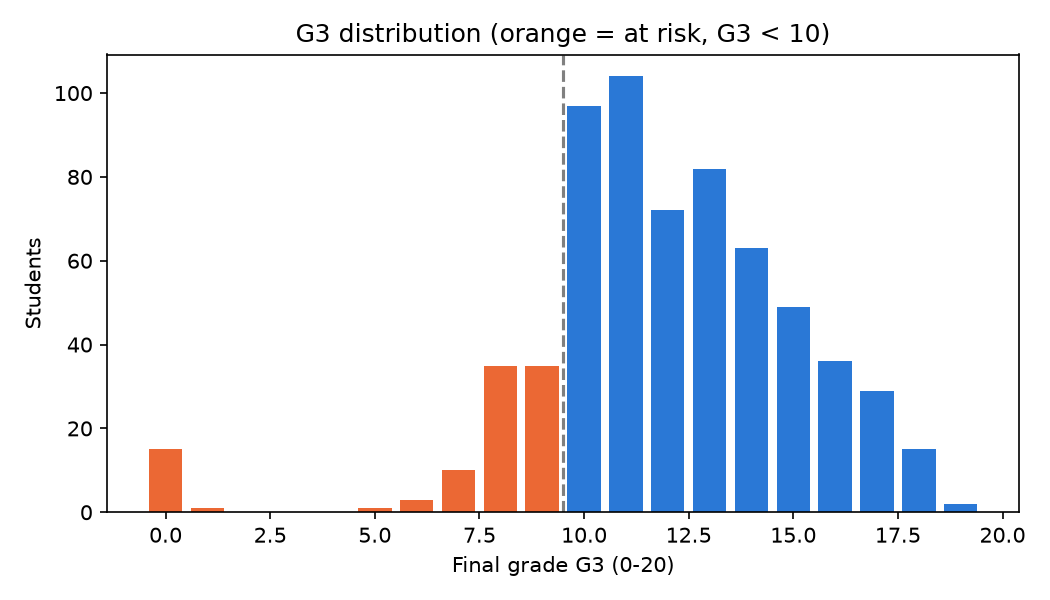

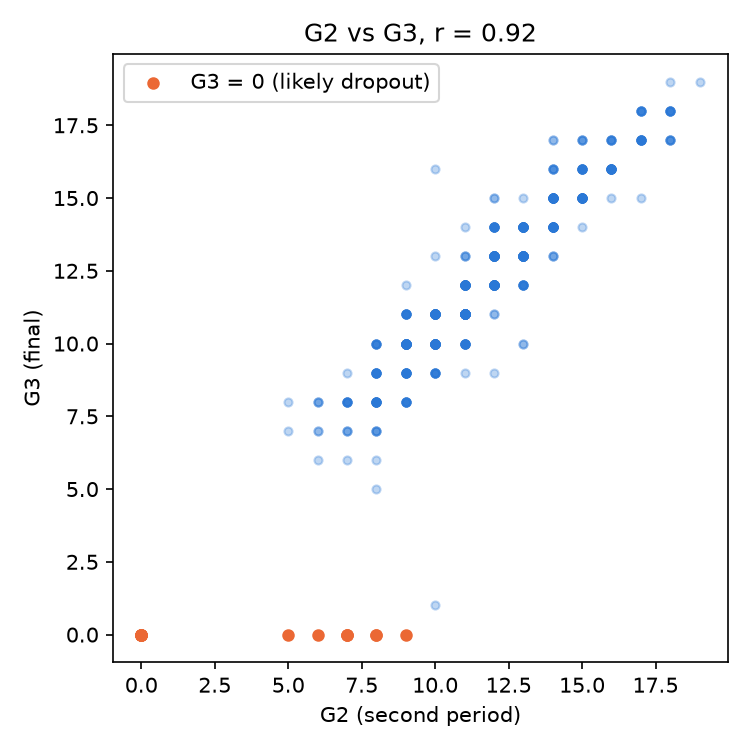

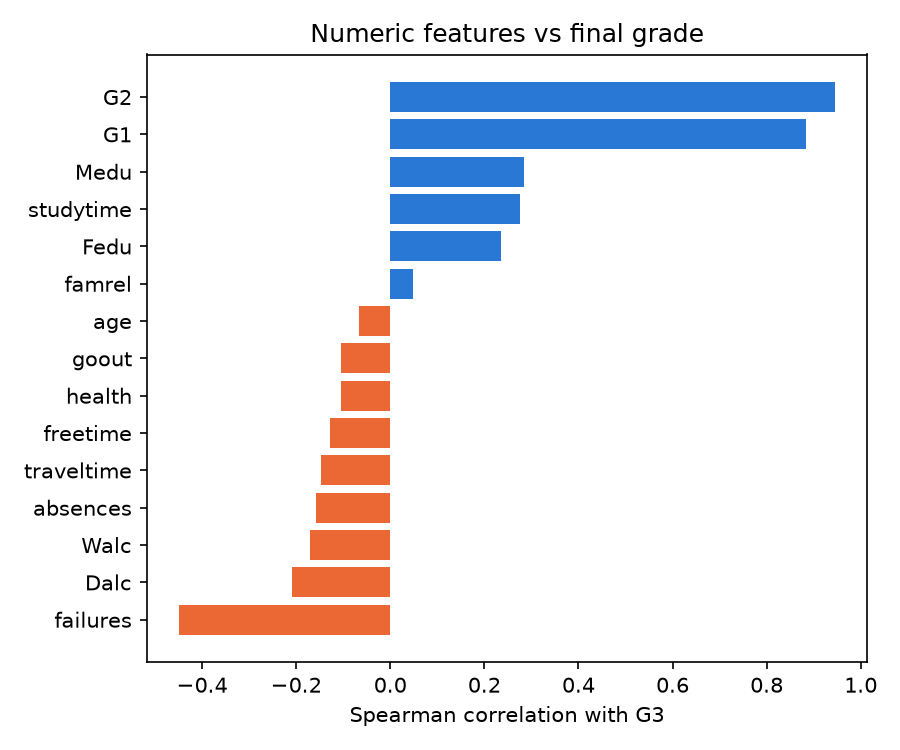

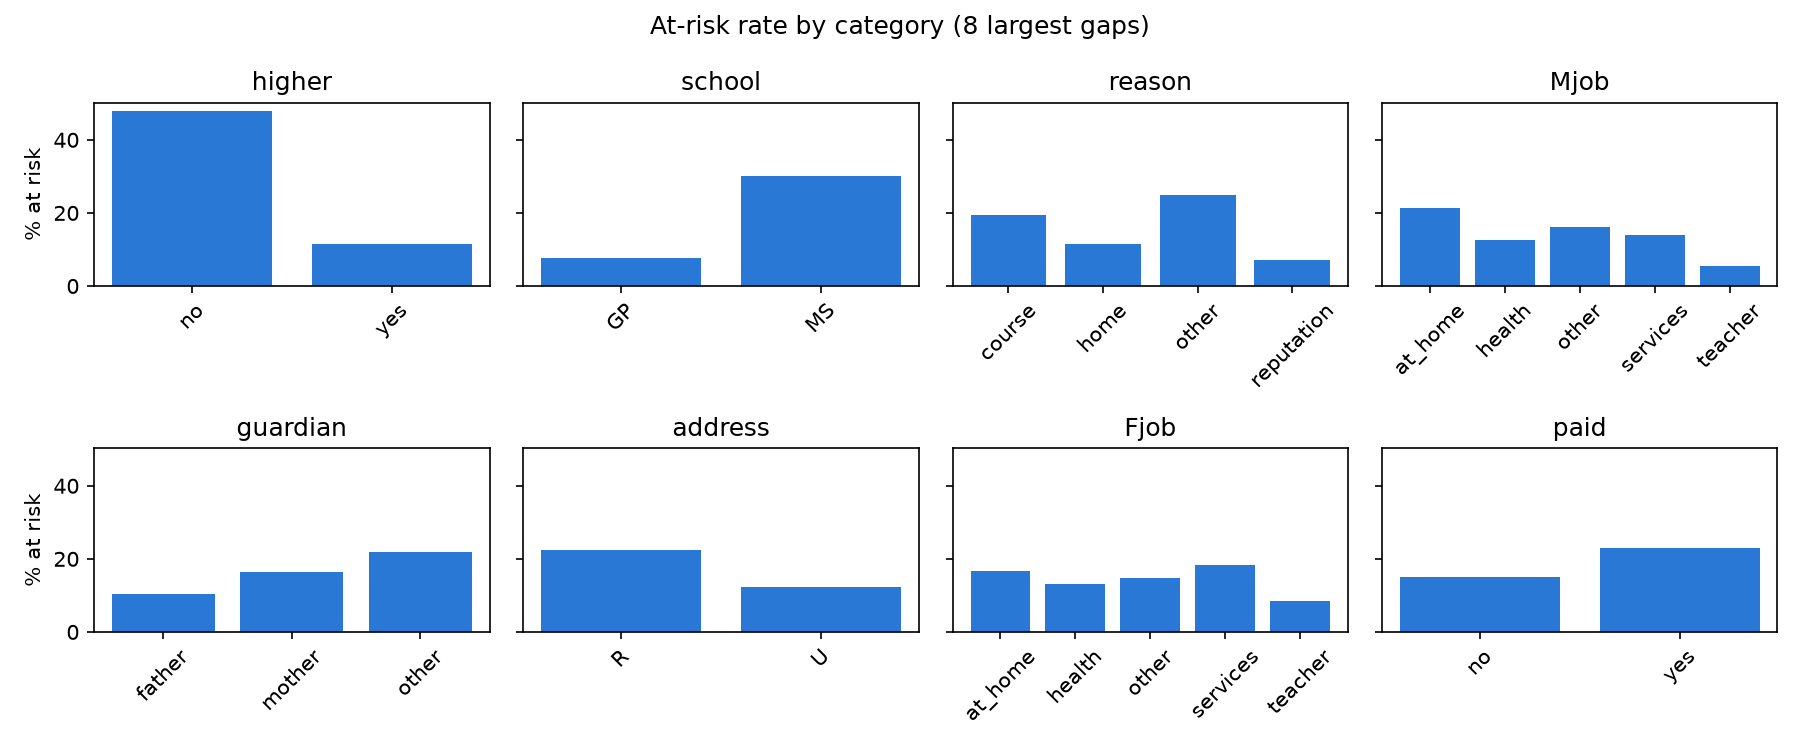

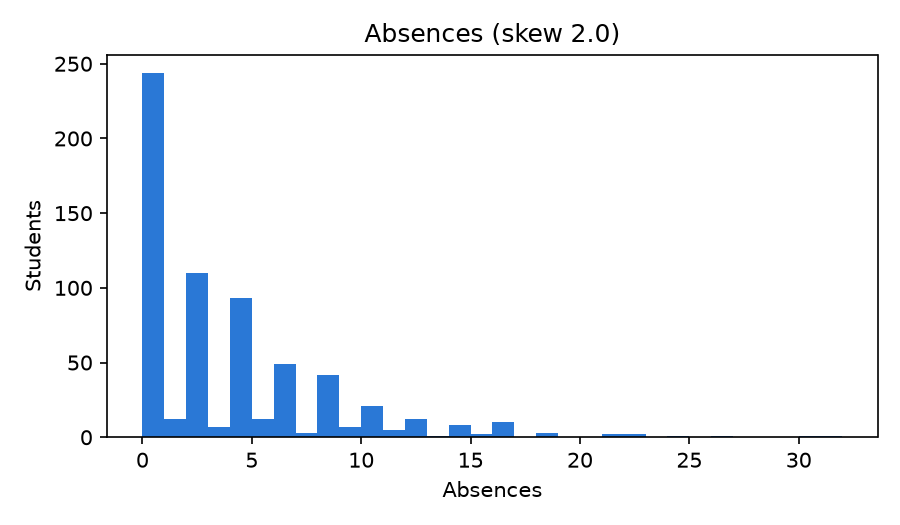

In [4]:
figures(df)  # saves the EDA plots to results/figures/
for name in ["g3_distribution", "g2_vs_g3", "correlations", "risk_by_category", "absences"]:
    display(Image(f"results/figures/{name}.png", width=700))

## 3. Target and locked test split

The target is `at_risk = G3 < 10`. The data is split 80/20 with stratification, so both parts keep the 15.4% at-risk share.
The 20% test set is **locked**: it is used once, in section 8, after all tuning is finished.

In [5]:
train, test = split(df)
print(f"train: {len(train)} students, {train.at_risk.mean():.1%} at risk")
print(f"test:  {len(test)} students, {test.at_risk.mean():.1%} at risk  (locked until section 8)")

train: 519 students, 15.4% at risk
test:  130 students, 15.4% at risk  (locked until section 8)


## 4. Preprocessing and feature selection

- **One-hot encoding** for nominal columns such as Mjob or reason, so no fake order is invented.
- **Standardisation** for numeric and ordinal columns, so every input has a similar scale for gradient descent.
- **SelectKBest with mutual information** keeps the k most informative columns. Optuna chose k = 10 for late term.

All three are steps of a scikit-learn `Pipeline`. During cross-validation they are refit on each training fold only, so no statistic from a validation or test student leaks into training.

32 input columns (30 features + G1, G2) -> 45 after one-hot encoding -> 10 kept


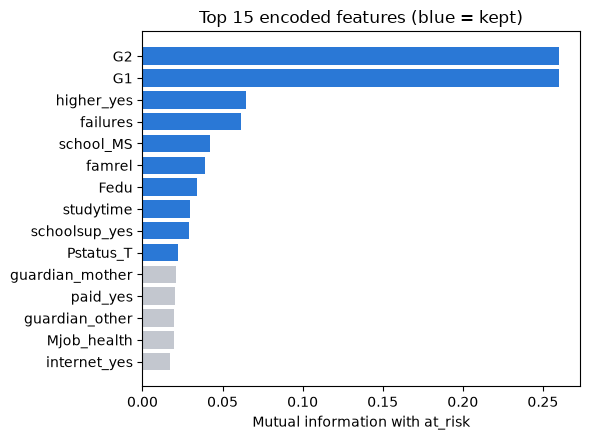

In [6]:
pre = Pipeline(make_preprocessor("late", k=10)).fit(train, train.at_risk)
encoded = pre.named_steps["encode"].transform(train)
mi = pd.Series(pre.named_steps["select"].scores_, index=encoded.columns).sort_values()
print(f"32 input columns (30 features + G1, G2) -> {encoded.shape[1]} after one-hot encoding -> 10 kept")

top = mi.tail(15)
plt.figure(figsize=(6, 4.5))
plt.barh(top.index, top.values, color=["#2a78d6" if c in pre.named_steps["select"].get_feature_names_out() else "#c3c7cf" for c in top.index])
plt.xlabel("Mutual information with at_risk"); plt.title("Top 15 encoded features (blue = kept)"); plt.tight_layout(); plt.show()

## 5. The DNN: architecture and training loop

The late-term network Optuna chose has **10 inputs → 64 → 32 → 16 → 1 output**. Each hidden layer is `Linear → BatchNorm → ReLU → Dropout`.
- **He initialisation** suits ReLU.
- The single output is a **logit**. `BCEWithLogitsLoss` combines the sigmoid and the binary cross-entropy in one numerically stable step.
- The final model is a **seed ensemble**: 5 networks trained from different random starts, with their probabilities averaged.

In [7]:
net = MLP(n_inputs=10, hidden=(64, 32, 16), dropout=0.16, batchnorm=True)
print(net)
print("trainable parameters:", sum(p.numel() for p in net.parameters() if p.requires_grad))

MLP(
  (net): Sequential(
    (0): Linear(in_features=10, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.16, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.16, inplace=False)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.16, inplace=False)
    (12): Linear(in_features=16, out_features=1, bias=True)
  )
)
trainable parameters: 3553


The training loop below does **zero_grad → forward pass → loss → backward (backpropagation) → optimizer step**, one mini-batch at a time.

Early stopping uses 15% of the *training* rows, never the test set. When validation loss has not improved for 30 epochs, training stops and the weights from the best epoch are restored.

In [8]:
print(inspect.getsource(DNNClassifier._train_one))

    def _train_one(self, X, y, seed):
        torch.manual_seed(seed)
        # Hold out 15% of the training rows to decide when to stop (never the test set).
        X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.15, stratify=y, random_state=seed)
        X_tr, y_tr, X_val, y_val = map(torch.from_numpy, (X_tr, y_tr, X_val, y_val))

        model = MLP(X.shape[1], self.hidden, self.dropout, self.batchnorm)
        # AdamW = Adam with decoupled weight decay (L2-style regularisation).
        optimizer = torch.optim.AdamW(model.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        # Only ~15% of students fail. pos_weight = (#pass / #fail) makes each missed failure cost as much
        # as all the passes it is outnumbered by, so the model can't ignore the minority class.
        pos_weight = (len(y_tr) - y_tr.sum()) / y_tr.sum() if self.class_weight else torch.tensor(1.0)
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)  # sigmoid + binary cross-en

## 6. Hardware: CPU vs GPU

The brief asks for a hardware benchmark. This cell trains the same network for 50 epochs on every available device: the CPU, plus an NVIDIA GPU (`cuda`, on Kaggle) or an Apple GPU (`mps`, on a Mac) if present.
The network has only a few thousand weights and each batch holds 32 rows, so the cost of launching GPU work can outweigh the maths it saves.

In [9]:
X_bench, y_bench = torch.randn(519, 45), (torch.rand(519) < 0.15).float()

def bench(device, epochs=50):
    torch.manual_seed(0)
    model = MLP(45, (64, 32, 16), 0.16, True).to(device)
    opt, loss_fn = torch.optim.AdamW(model.parameters(), lr=1e-3), torch.nn.BCEWithLogitsLoss()
    X, y = X_bench.to(device), y_bench.to(device)
    start = time.perf_counter()
    for _ in range(epochs):
        for i in range(0, len(X), 32):
            opt.zero_grad(); loss_fn(model(X[i:i + 32]), y[i:i + 32]).backward(); opt.step()
    if device == "cuda": torch.cuda.synchronize()
    if device == "mps": torch.mps.synchronize()
    return time.perf_counter() - start

devices = ["cpu"] + ["cuda"] * torch.cuda.is_available() + ["mps"] * torch.backends.mps.is_available()
for d in devices:
    bench(d, epochs=2)  # warm-up (first GPU call pays a one-off start-up cost)
    print(f"{d:5s} {bench(d):.2f} s for 50 epochs" + (f"  ({torch.cuda.get_device_name()})" if d == "cuda" else ""))

cpu   0.38 s for 50 epochs


mps   1.05 s for 50 epochs


## 7. Hyperparameter tuning with Optuna

Optuna's TPE sampler searched 9 hyperparameters: depth, width, dropout, BatchNorm, learning rate, weight decay, batch size, class weights and the number of features k.
It ran 40 trials per scenario, and each trial was scored by **5-fold CV macro-F1 on the training set only**. Every trial is logged in `results/experiments.csv`.
Re-running the search takes about 10 minutes, so by default this section loads the saved log. Set `RUN_TUNING = True` to run it again.

In [10]:
print(inspect.getsource(tune.objective).split("cv = ")[0])  # the search space

def objective(trial, scenario, train):
    params = {
        "n_layers": trial.suggest_int("n_layers", 1, 3),
        "width": trial.suggest_categorical("width", [16, 32, 64, 128]),
        "dropout": trial.suggest_float("dropout", 0.0, 0.5),
        "batchnorm": trial.suggest_categorical("batchnorm", [True, False]),
        "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-5, 1e-2, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [16, 32, 64]),
        "class_weight": trial.suggest_categorical("class_weight", [True, False]),
        "k": trial.suggest_categorical("k", [10, 15, 20, "all"]),
    }
    


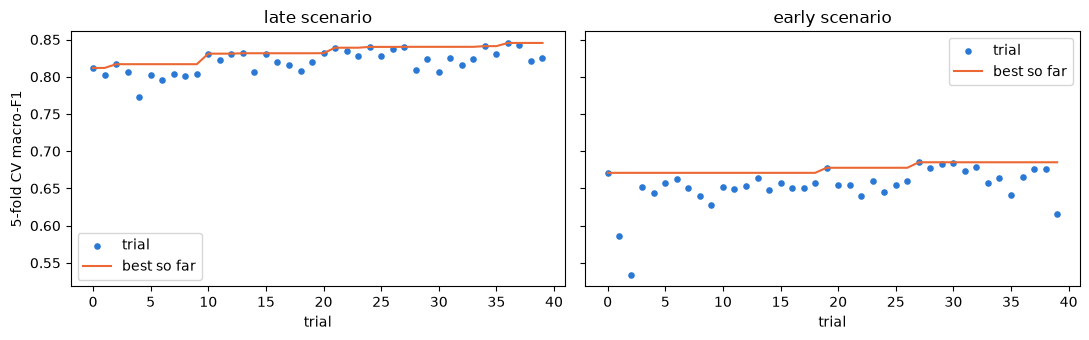

,scenario,trial,n_layers,width,dropout,batchnorm,lr,batch_size,class_weight,k,cv_f1_macro,cv_f1_std
36,late,36,3,64,0.1620,True,0.0009,64,False,10,0.8455,0.0743
37,late,37,3,64,0.2734,True,0.0013,64,False,10,0.8425,0.0801
34,late,34,3,64,0.1621,True,0.0012,64,False,10,0.8412,0.0641
67,early,27,3,16,0.1256,False,0.0014,32,True,20,0.6852,0.0671
70,early,30,3,16,0.1348,False,0.0023,32,True,20,0.6844,0.0647
69,early,29,3,16,0.1363,False,0.0011,32,True,20,0.6826,0.0699


{'late': {'n_layers': 3,
  'width': 64,
  'dropout': 0.16199217271219457,
  'batchnorm': True,
  'lr': 0.0009152887329124827,
  'weight_decay': 1.7588952092273983e-05,
  'batch_size': 64,
  'class_weight': False,
  'k': 10},
 'early': {'n_layers': 3,
  'width': 16,
  'dropout': 0.1255700596373297,
  'batchnorm': False,
  'lr': 0.0013624140903810116,
  'weight_decay': 0.004701002013683422,
  'batch_size': 32,
  'class_weight': True,
  'k': 20}}

In [11]:
RUN_TUNING = False  # True re-runs all 80 trials and overwrites results/best_params.json
if RUN_TUNING:
    tune.main()

trials = pd.read_csv("results/experiments.csv")
best = json.load(open("results/best_params.json"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, s in zip(axes, ["late", "early"]):
    t = trials[trials.scenario == s]
    ax.scatter(t.trial, t.cv_f1_macro, s=14, color="#2a78d6", label="trial")
    ax.plot(t.trial, t.cv_f1_macro.cummax(), color="#eb6834", label="best so far")
    ax.set(title=f"{s} scenario", xlabel="trial"); ax.legend()
axes[0].set_ylabel("5-fold CV macro-F1"); plt.tight_layout(); plt.show()

cols = ["scenario", "trial", "n_layers", "width", "dropout", "batchnorm", "lr", "batch_size", "class_weight", "k", "cv_f1_macro", "cv_f1_std"]
display(trials.sort_values("cv_f1_macro", ascending=False).groupby("scenario").head(3)[cols].round(4))
best

## 8. DNN vs traditional ML, then the test set

`evaluate.main()` does the following for each scenario:
1. Grid-searches logistic regression, random forest and XGBoost with the same CV and metric the DNN was tuned with, so the comparison is fair.
2. Scores every model with **5-fold × 3-repeat CV** on the training set.
3. Refits each model on all 519 training students and scores the **130 locked test students once**.
4. Repeats the DNN test score over 5 seeds and adds a bootstrap 95% confidence interval.
5. Saves the DNN pipelines that the Streamlit app uses, the figures and `results/RESULTS.md`.

In [12]:
evaluate.main()


=== late scenario ===


  Logistic regression: {'model__C': 10, 'model__class_weight': 'balanced', 'select__k': 20}


  Random forest: {'model__class_weight': 'balanced_subsample', 'model__max_depth': 6, 'model__min_samples_leaf': 5}


  XGBoost: {'model__max_depth': 3, 'model__n_estimators': 400, 'model__scale_pos_weight': 5.5}
  Majority class         CV macro-F1 0.458 | test acc 0.846


  Naive rule (G2 < 10)   CV macro-F1 0.831 | test acc 0.900


  Logistic regression    CV macro-F1 0.851 | test acc 0.892


... (8 outputs left out)

  Random forest          CV macro-F1 0.721 | test acc 0.838


  XGBoost                CV macro-F1 0.711 | test acc 0.808


  DNN (MLP)              CV macro-F1 0.687 | test acc 0.762



Wrote results/RESULTS.md and models/dnn_late.joblib, models/dnn_early.joblib


In [13]:
metrics = json.load(open("results/metrics.json"))
show = {"cv_f1_macro": "CV macro-F1", "cv_f1_macro_std": "± std", "cv_accuracy": "CV acc", "cv_balanced_acc": "CV bal. acc",
        "cv_recall_at_risk": "CV recall", "test_accuracy": "Test acc", "test_f1_macro": "Test macro-F1",
        "test_recall_at_risk": "Test recall", "test_roc_auc": "Test ROC-AUC"}
for s in ["late", "early"]:
    rows, extra = metrics[s]
    display(Markdown(f"### {s} scenario"))
    display(pd.DataFrame(rows).T[list(show)].rename(columns=show).astype(float).style.format("{:.3f}"))
    m, sd, ci = extra["seed_mean"], extra["seed_std"], extra["bootstrap_95ci"]
    print(f"DNN over 5 seeds (test): accuracy {m['accuracy']:.3f} ± {sd['accuracy']:.3f}, macro-F1 {m['f1_macro']:.3f} ± {sd['f1_macro']:.3f}")
    print(f"Bootstrap 95% CI of test accuracy: {ci['accuracy'][0]:.3f} to {ci['accuracy'][1]:.3f}")
    print("Selected features:", ", ".join(extra["selected_features"]))

### late scenario

,CV macro-F1,± std,CV acc,CV bal. acc,CV recall,Test acc,Test macro-F1,Test recall,Test ROC-AUC
Majority class,0.458,0.000,0.846,0.500,0.000,0.846,0.458,0.000,0.500
Naive rule (G2 < 10),0.831,0.046,0.896,0.893,0.887,0.900,0.837,0.900,0.953
Logistic regression,0.851,0.043,0.912,0.900,0.883,0.892,0.827,0.900,0.946
Random forest,0.867,0.045,0.921,0.916,0.908,0.862,0.784,0.850,0.946
XGBoost,0.866,0.045,0.929,0.878,0.804,0.900,0.825,0.800,0.925
DNN (MLP),0.835,0.077,0.919,0.821,0.679,0.900,0.819,0.750,0.953


DNN over 5 seeds (test): accuracy 0.912 ± 0.004, macro-F1 0.843 ± 0.009
Bootstrap 95% CI of test accuracy: 0.846 to 0.946
Selected features: school_MS, Pstatus_T, schoolsup_yes, higher_yes, Fedu, studytime, failures, famrel, G1, G2


### early scenario

,CV macro-F1,± std,CV acc,CV bal. acc,CV recall,Test acc,Test macro-F1,Test recall,Test ROC-AUC
Majority class,0.458,0.000,0.846,0.500,0.000,0.846,0.458,0.000,0.500
Logistic regression,0.685,0.035,0.808,0.721,0.596,0.785,0.642,0.500,0.791
Random forest,0.721,0.041,0.855,0.718,0.521,0.838,0.653,0.350,0.790
XGBoost,0.711,0.045,0.838,0.727,0.567,0.808,0.652,0.450,0.743
DNN (MLP),0.687,0.033,0.795,0.744,0.671,0.762,0.622,0.500,0.797


DNN over 5 seeds (test): accuracy 0.803 ± 0.020, macro-F1 0.672 ± 0.032
Bootstrap 95% CI of test accuracy: 0.685 to 0.831
Selected features: school_MS, famsize_LE3, Mjob_teacher, Fjob_other, reason_home, guardian_other, schoolsup_yes, famsup_yes, paid_yes, higher_yes, internet_yes, romantic_yes, age, Medu, traveltime, failures, freetime, goout, Dalc, health


**late:** confusion matrix, ROC curves and learning curve

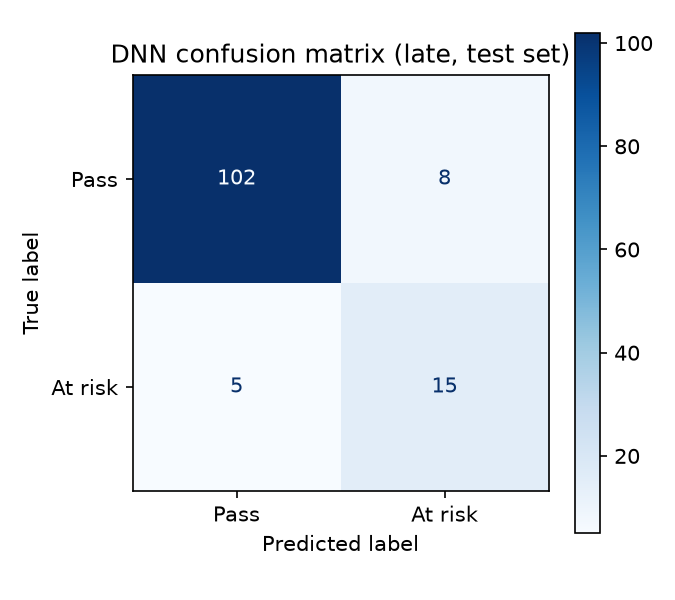

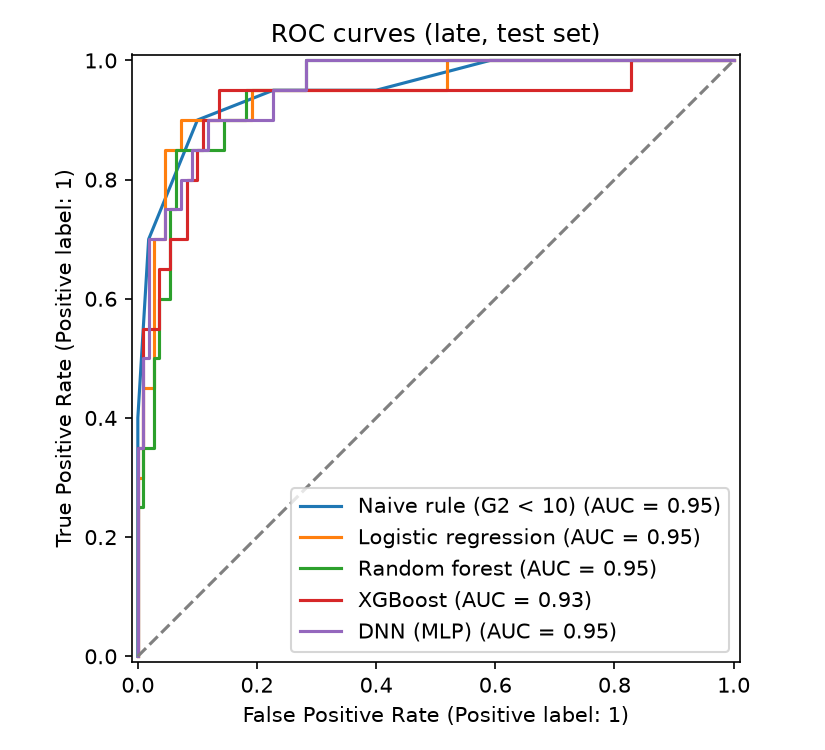

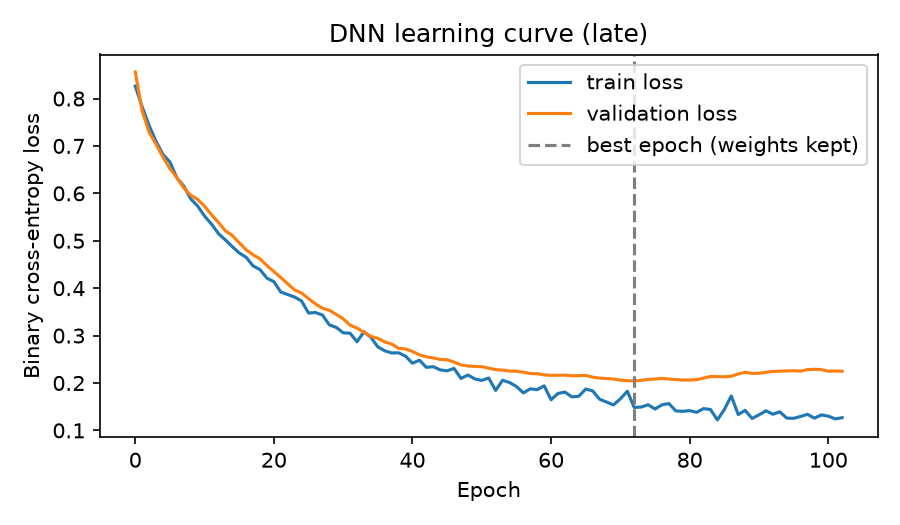

**early:** confusion matrix, ROC curves and learning curve

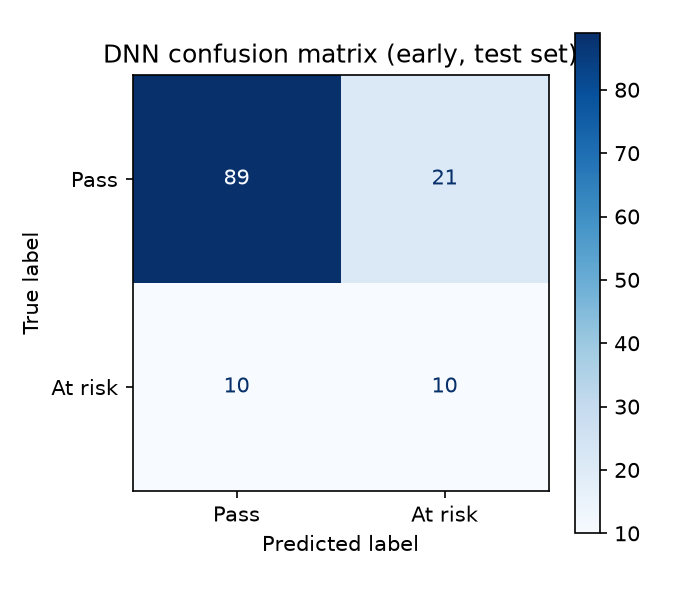

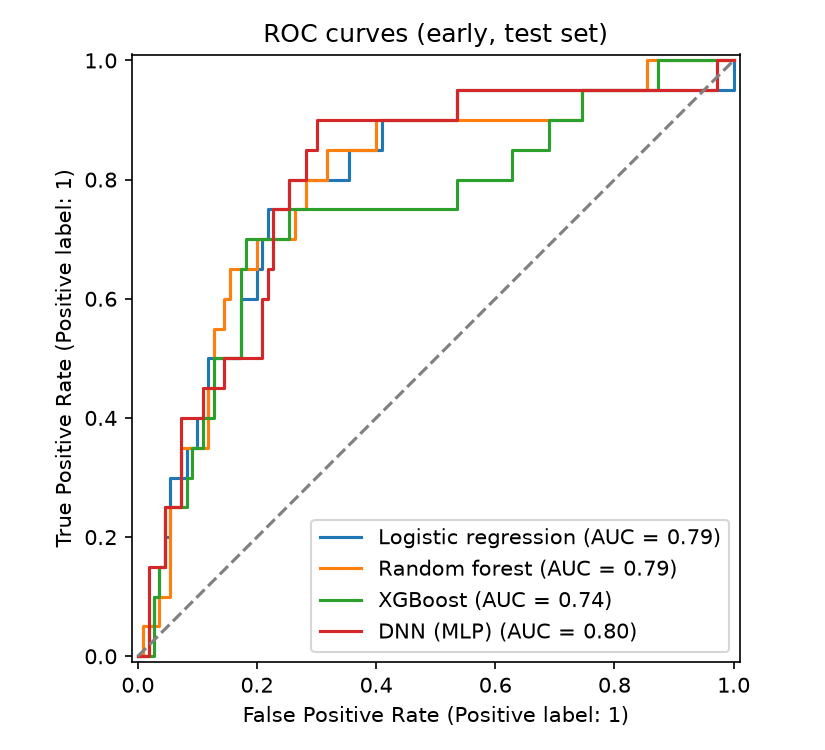

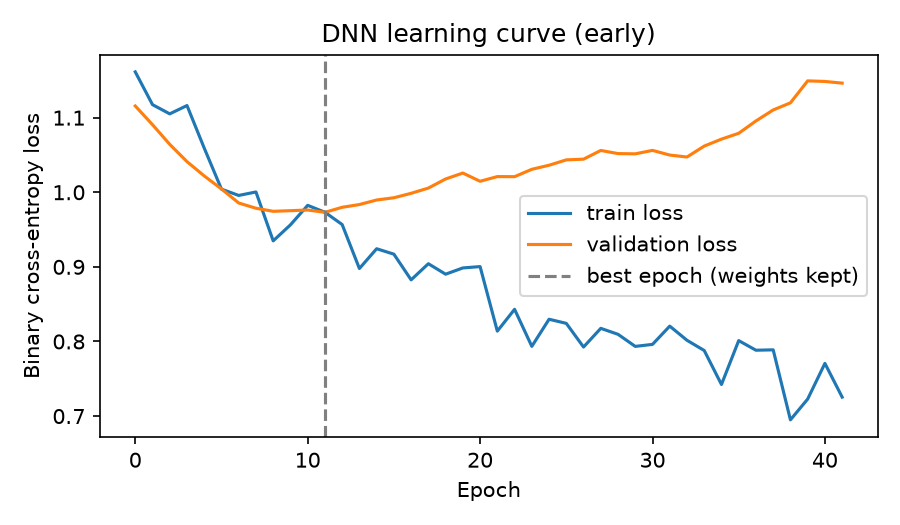

In [14]:
for s in ["late", "early"]:
    display(Markdown(f"**{s}:** confusion matrix, ROC curves and learning curve"))
    display(Image(f"results/figures/confusion_{s}.png", width=330), Image(f"results/figures/roc_{s}.png", width=380))
    display(Image(f"results/figures/learning_curve_{s}.png", width=560))

## 9. The same network in Keras

The course covers both TensorFlow/Keras and PyTorch, so this section rebuilds the late-term network with the Keras Sequential API. It uses the same inputs, the same layers and the same hyperparameters.

Keras provides through callbacks what the PyTorch loop writes by hand:
- `EarlyStopping(restore_best_weights=True)` does the same job as the patience loop.
- `ModelCheckpoint` saves the best model to disk.

This is a single network, so it is compared with a single PyTorch network rather than the 5-network ensemble.

In [15]:
import keras
from keras import layers
from sklearn.metrics import accuracy_score, f1_score

p = best["late"]
pre = Pipeline(make_preprocessor("late", p["k"])).fit(train, train.at_risk)  # same preprocessing, fitted on train only
X_tr, X_te = (np.asarray(pre.transform(d), dtype="float32") for d in (train, test))
y_tr, y_te = train.at_risk.to_numpy("float32"), test.at_risk.to_numpy()

keras.utils.set_random_seed(SEED)
model = keras.Sequential([keras.Input((X_tr.shape[1],))])
for units in [max(8, p["width"] // 2**i) for i in range(p["n_layers"])]:  # 64 -> 32 -> 16, as in build_dnn
    model.add(layers.Dense(units, kernel_initializer="he_normal"))
    if p["batchnorm"]:
        model.add(layers.BatchNormalization())
    model.add(layers.ReLU())
    model.add(layers.Dropout(p["dropout"]))
model.add(layers.Dense(1, activation="sigmoid"))
model.compile(optimizer=keras.optimizers.AdamW(learning_rate=p["lr"], weight_decay=p["weight_decay"]),
              loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

callbacks = [keras.callbacks.EarlyStopping(patience=30, restore_best_weights=True),
             keras.callbacks.ModelCheckpoint("models/keras_late.keras", save_best_only=True)]
history = model.fit(X_tr, y_tr, validation_split=0.15, epochs=300, batch_size=p["batch_size"], callbacks=callbacks, verbose=0)
keras_pred = (model.predict(X_te, verbose=0)[:, 0] >= 0.5).astype(int)

torch_single = tune.build_dnn(p, "late", n_models=1).fit(train, train.at_risk)
torch_pred = torch_single.predict(test)
print(f"Keras, 1 network:   stopped after {len(history.history['loss'])} epochs, "
      f"test accuracy {accuracy_score(y_te, keras_pred):.3f}, macro-F1 {f1_score(y_te, keras_pred, average='macro'):.3f}")
print(f"PyTorch, 1 network: test accuracy {accuracy_score(y_te, torch_pred):.3f}, macro-F1 {f1_score(y_te, torch_pred, average='macro'):.3f}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,777 (14.75 KB)

 Trainable params: 3,553 (13.88 KB)

 Non-trainable params: 224 (896.00 B)

Keras, 1 network:   stopped after 105 epochs, test accuracy 0.885, macro-F1 0.811
PyTorch, 1 network: test accuracy 0.908, macro-F1 0.830


## 10. What the network computes, in plain NumPy

A trained network is matrix multiplications plus simple element-wise functions. This cell takes the first network of the saved late-term ensemble and recomputes its predictions on the test set using only NumPy. The NumPy result matches PyTorch to within floating-point rounding.
- At prediction time, BatchNorm uses the **running mean and variance** collected during training.
- Dropout does nothing at prediction time.

In [16]:
dnn = joblib.load("models/dnn_late.joblib")
X = np.asarray(dnn[:-1].transform(test), dtype="float32")  # every pipeline step except the model: encode + select
net = dnn.named_steps["model"].models_[0].net      # first network of the ensemble

h = X
for layer in net:
    if isinstance(layer, torch.nn.Linear):          # h = h W^T + b
        h = h @ layer.weight.detach().numpy().T + layer.bias.detach().numpy()
    elif isinstance(layer, torch.nn.BatchNorm1d):   # normalise with running statistics, then scale and shift
        h = (h - layer.running_mean.numpy()) / np.sqrt(layer.running_var.numpy() + layer.eps)
        h = h * layer.weight.detach().numpy() + layer.bias.detach().numpy()
    elif isinstance(layer, torch.nn.ReLU):
        h = np.maximum(h, 0)
p_numpy = 1 / (1 + np.exp(-h[:, 0]))               # sigmoid turns the logit into P(at risk)

with torch.no_grad():
    p_torch = torch.sigmoid(net(torch.from_numpy(X))).numpy()[:, 0]
print("largest difference between NumPy and PyTorch:", np.abs(p_numpy - p_torch).max())
assert np.allclose(p_numpy, p_torch, atol=1e-5)

largest difference between NumPy and PyTorch: 1.4901161e-07


## 11. Predicting individual students

This is what the Streamlit app (`streamlit run app.py`) does: it passes one row of raw student data through the saved pipeline (encode → select → 5-network ensemble) and reads off the probability.

In [17]:
sample = pd.concat([test[test.at_risk == 1].head(3), test[test.at_risk == 0].head(3)])
out = sample[["G1", "G2", "failures", "absences", "studytime", "higher", "G3"]].copy()
out["P(at risk)"] = dnn.predict_proba(sample)[:, 1].round(3)
out["predicted"] = np.where(out["P(at risk)"] >= 0.5, "at risk", "on track")
out["actual"] = np.where(sample.at_risk == 1, "at risk", "on track")
out

,G1,G2,failures,absences,studytime,higher,G3,P(at risk),predicted,actual
256,7,8,1,26,1,no,8,0.838,at risk,at risk
168,7,8,0,0,2,yes,8,0.719,at risk,at risk
646,11,12,0,6,2,yes,9,0.031,on track,at risk
21,11,12,0,0,1,yes,12,0.018,on track,on track
208,13,12,0,0,1,yes,12,0.012,on track,on track
278,9,12,0,2,1,yes,13,0.038,on track,on track


## 12. Conclusions

- **Late term (with G1, G2):** the DNN scores **0.900** test accuracy and **0.912 ± 0.004** over 5 seeds, with a test ROC-AUC of 0.953. That is level with XGBoost and the "G2 < 10" rule. With the period grades available, about 90% is the ceiling for every reasonable model on this data.
- **Early warning (no grades):** no model beats "everyone passes" (84.6%) on accuracy. The DNN has the **best CV balanced accuracy (0.744) and at-risk recall (0.671)**, which is what an early-warning tool needs. Random forest has the best CV macro-F1 (0.721).
- **Why the DNN does not win outright:** on small tabular datasets, tree ensembles are still as strong as or stronger than neural networks (Grinsztajn et al., NeurIPS 2022). Matching them with a leakage-free setup is the honest result.
- **Hardware:** see section 6. The network is tiny, so a GPU brings no benefit.
- **Limitations:** 649 students from two schools in 2005–06, and a 130-student test set, where one student moves accuracy by 0.8 points. The inputs include sensitive attributes, so a model like this should start a conversation with a student, not make decisions about them.

Every decision and its evidence is in `DECISIONS.md`. Full tables are in `results/RESULTS.md`.